In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torch.utils.data import TensorDataset
from scipy.spatial.distance import pdist
import torch.nn.functional as F

from LJ13.score import ScoreNetwork
from LJ13.data import load_configs, center_configs, configs_to_tensor
from LJ13.sde import VESDE, estimate_sigma_max
from LJ13.train import train_model
from LJ13.sampling import predictor_corrector_sampler
from LJ13.analysis import lj_energy_batch, pairwise_distances_batch, effective_temperature
from LJ13.langevin import langevin_push

In [ ]:
training_configs = load_configs("LJ13_configs.npy", n_atoms=13, n_dim=3)
training_configs_centered = center_configs(training_configs)
training_configs_centered_tensor = configs_to_tensor(training_configs_centered)
print(training_configs_centered_tensor.shape)

torch.Size([24994, 13, 3])


In [ ]:
flat = training_configs_centered.reshape(training_configs_centered.shape[0], -1)
sigma_max = estimate_sigma_max(flat, n_subset=len(flat))
print("sigma_max:", sigma_max)

train_sde = VESDE(sigma_max=sigma_max, sigma_min=0.02)

sigma_max: 6.440439591617135


In [ ]:
equivariant_model = ScoreNetwork(hidden_dim=64, num_layers=3)

equivariant_model.load_state_dict(torch.load("lj13_f_theta_strategy_1.pth"))

equivariant_model.eval()

ScoreNetwork(
  (embedding): Linear(in_features=1, out_features=64, bias=True)
  (layers): ModuleList(
    (0-2): 3 x EGNNLayer(
      (message_mlp): MessageMLP(
        (net): Sequential(
          (0): Linear(in_features=130, out_features=64, bias=True)
          (1): SiLU()
          (2): Linear(in_features=64, out_features=64, bias=True)
          (3): SiLU()
        )
      )
      (feature_mlp): FeatureMLP(
        (net): Sequential(
          (0): Linear(in_features=128, out_features=64, bias=True)
          (1): SiLU()
          (2): Linear(in_features=64, out_features=64, bias=True)
        )
      )
      (coord_mlp): CoordMLP(
        (net): Sequential(
          (0): Linear(in_features=130, out_features=64, bias=True)
          (1): SiLU()
          (2): Linear(in_features=64, out_features=64, bias=True)
          (3): SiLU()
          (4): Linear(in_features=64, out_features=1, bias=True)
        )
      )
    )
  )
)

In [ ]:
sample_sde = VESDE(sigma_max=sigma_max, sigma_min=0.01)

equivariant_samples = predictor_corrector_sampler(
    equivariant_model,
    sample_sde,
    n_samples=1000,
    n_steps=1000,
    n_corrector=1,
    snr=0.16,
)

In [19]:
equivariant_samples_LP = langevin_push(
    equivariant_samples,
    n_steps=200,
    step_size=1e-5,
    temperature=0.1
)

In [ ]:
equivariant_generated_energies = lj_energy_batch(equivariant_samples).cpu().numpy()
training_energies = lj_energy_batch(training_configs_centered_tensor).cpu().numpy()
equivariant_generated_energies_LP = lj_energy_batch(equivariant_samples_LP).cpu().numpy()

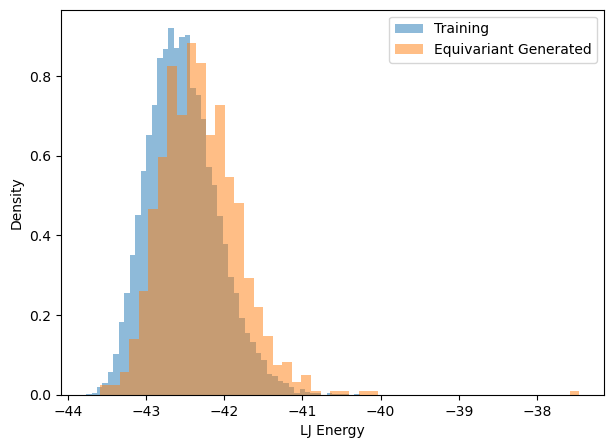

In [23]:
plt.figure(figsize=(7,5))

plt.hist(training_energies,
         bins=50,
         density=True,
         alpha=0.5,
         label="Training")

plt.hist(equivariant_generated_energies,
         bins=50,
         density=True,
         alpha=0.5,
         label="Equivariant Generated")

plt.xlabel("LJ Energy")
plt.ylabel("Density")
plt.legend()
plt.show()

In [24]:
width = 128
depth = 3

layers = []

layers.append(nn.Linear(40, width))
layers.append(nn.ReLU())

for _ in range(depth - 1):
    layers.append(nn.Linear(width, width))
    layers.append(nn.ReLU())

layers.append(nn.Linear(width, 39))

baseline_model = nn.Sequential(*layers)

In [25]:
checkpoint = torch.load(
    "baseline_model_data.pth",
    weights_only=True
)

baseline_model.load_state_dict(checkpoint["model_state_dict"])
baseline_loss_history = checkpoint["loss_history"]

baseline_model.eval()

Sequential(
  (0): Linear(in_features=40, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=128, bias=True)
  (3): ReLU()
  (4): Linear(in_features=128, out_features=128, bias=True)
  (5): ReLU()
  (6): Linear(in_features=128, out_features=39, bias=True)
)

In [ ]:
sigma_min = 0.01

def get_sigma(t):

    return sigma_min * (sigma_max/sigma_min)**t

def g(t):

    sigma = get_sigma(t)

    return (sigma * np.sqrt(2*np.log(sigma_max/sigma_min)))

In [26]:
def baseline_predictor_corrector_sampler(
    model,
    n_samples=1000,
    n_steps=1000,
    n_corrector=1,
    snr=0.16
):

    model.eval()

    x = torch.randn(n_samples, 39) * sigma_max

    dt = 1.0 / n_steps
    sqrt_dt = np.sqrt(dt)


    with torch.no_grad():

        for i in range(n_steps):

            t = 1 - i / n_steps

            t_tensor = torch.full((n_samples,1), t)

            sigma = get_sigma(t_tensor)

            g_val = g(t_tensor)


            model_input = torch.cat([x, sigma], dim=1)

            score = model(model_input)


            noise = torch.randn_like(x)

            x = (x + (g_val**2) * score * dt + g_val * sqrt_dt * noise)


            for _ in range(n_corrector):

                sigma = get_sigma(t_tensor)

                model_input = torch.cat([x, sigma], dim=1)

                score = model(model_input)

                noise = torch.randn_like(x)

                score_norm = torch.norm(score.reshape(n_samples, -1), dim=1).mean()


                noise_norm = torch.norm(noise.reshape(n_samples,-1), dim=1).mean()

                eps = (2 * (snr * noise_norm / score_norm)**2)
                eps = torch.clamp(eps, max=0.05)

                x = (x + eps * score + torch.sqrt(2*eps) * noise)


    return x

In [27]:
baseline_samples = baseline_predictor_corrector_sampler(baseline_model, n_samples=1000, n_steps=1000, n_corrector=1, snr=0.16)

In [28]:
baseline_generated_energies = []

for sample in baseline_samples:

    sample = sample.reshape(13, 3)

    E = lj_energy_batch(sample.unsqueeze(0)).item()

    baseline_generated_energies.append(E)

baseline_generated_energies = np.array(baseline_generated_energies)

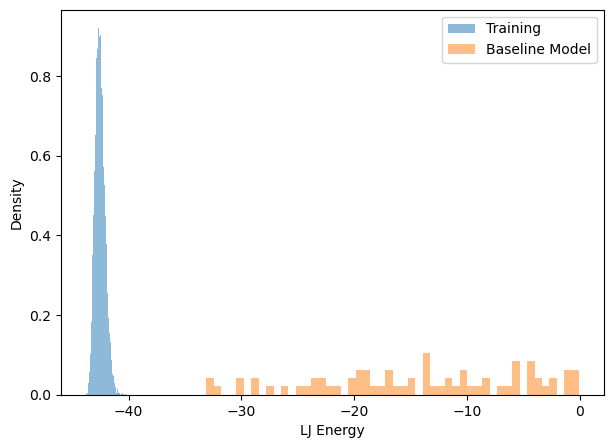

In [29]:
plt.figure(figsize=(7,5))

plt.hist(training_energies,
         bins=50,
         density=True,
         alpha=0.5,
         label="Training")

plt.hist(baseline_generated_energies[baseline_generated_energies < 0],
         bins=50,
         density=True,
         alpha=0.5,
         label="Baseline Model")

plt.xlabel("LJ Energy")
plt.ylabel("Density")
plt.legend()
plt.show()

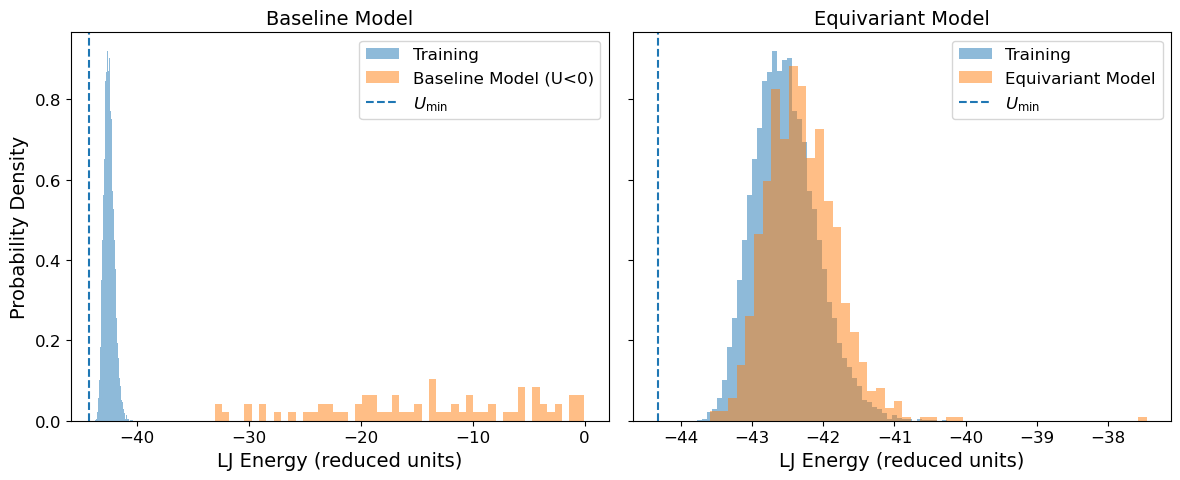

In [35]:
U_min = -44.3268

plt.rcParams.update({
    "font.size": 13,
    "axes.labelsize": 14,
    "axes.titlesize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
})

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# -------------------------
# Left: Baseline
# -------------------------
axes[0].hist(
    training_energies,
    bins=50,
    density=True,
    alpha=0.5,
    label="Training"
)

axes[0].hist(
    baseline_generated_energies[baseline_generated_energies < 0],
    bins=50,
    density=True,
    alpha=0.5,
    label="Baseline Model (U<0)"
)

axes[0].axvline(
    U_min,
    linestyle="--",
    label=r"$U_{\min}$"
)

axes[0].set_xlabel("LJ Energy (reduced units)")
axes[0].set_ylabel("Probability Density")
axes[0].set_title("Baseline Model")
axes[0].legend()


# -------------------------
# Right: Equivariant
# -------------------------
axes[1].hist(
    training_energies,
    bins=50,
    density=True,
    alpha=0.5,
    label="Training"
)

axes[1].hist(
    equivariant_generated_energies,
    bins=50,
    density=True,
    alpha=0.5,
    label="Equivariant Model"
)

axes[1].axvline(
    U_min,
    linestyle="--",
    label=r"$U_{\min}$"
)

axes[1].set_xlabel("LJ Energy (reduced units)")
axes[1].set_title("Equivariant Model")
axes[1].legend()

plt.tight_layout()
plt.savefig("energy_distributions.pdf", bbox_inches="tight")
plt.show()

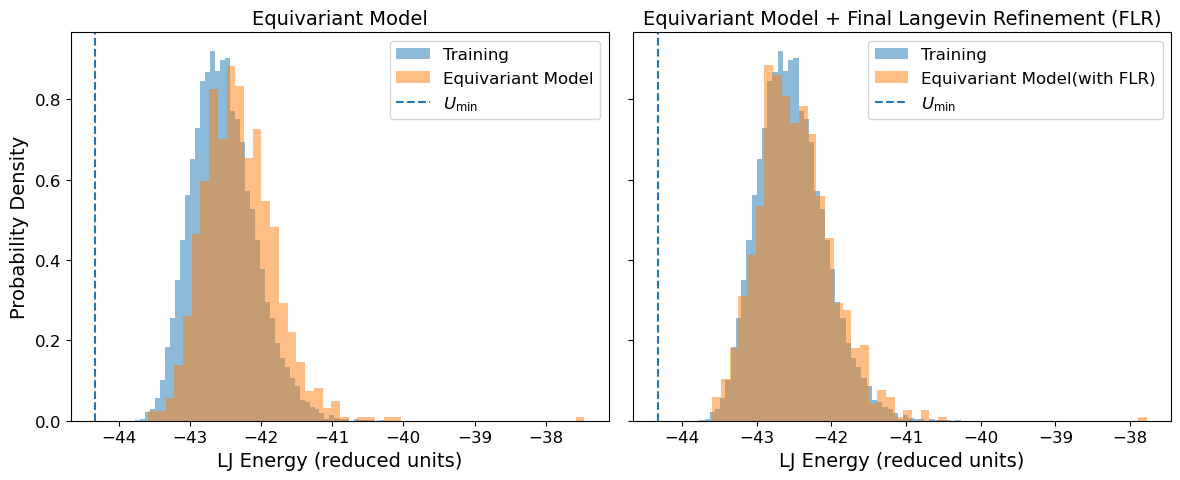

In [34]:
U_min = -44.3268

plt.rcParams.update({
    "font.size": 13,
    "axes.labelsize": 14,
    "axes.titlesize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
})

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# -------------------------
# Left: Baseline
# -------------------------
axes[0].hist(
    training_energies,
    bins=50,
    density=True,
    alpha=0.5,
    label="Training"
)

axes[0].hist(
    equivariant_generated_energies,
    bins=50,
    density=True,
    alpha=0.5,
    label="Equivariant Model"
)

axes[0].axvline(
    U_min,
    linestyle="--",
    label=r"$U_{\min}$"
)

axes[0].set_xlabel("LJ Energy (reduced units)")
axes[0].set_ylabel("Probability Density")
axes[0].set_title("Equivariant Model")
axes[0].legend()


# -------------------------
# Right: Equivariant
# -------------------------
axes[1].hist(
    training_energies,
    bins=50,
    density=True,
    alpha=0.5,
    label="Training"
)

axes[1].hist(
    equivariant_generated_energies_LP,
    bins=50,
    density=True,
    alpha=0.5,
    label="Equivariant Model(with FLR)"
)

axes[1].axvline(
    U_min,
    linestyle="--",
    label=r"$U_{\min}$"
)

axes[1].set_xlabel("LJ Energy (reduced units)")
axes[1].set_title("Equivariant Model + Final Langevin Refinement (FLR)")
axes[1].legend()

plt.tight_layout()
plt.savefig("energy_refinement.pdf", bbox_inches="tight")
plt.show()

In [36]:
valid = baseline_generated_energies < 0
valid_configs = baseline_samples[valid]
print(len(valid_configs), "valid configurations")

ratio_valid_samples = len(valid_configs) / len(baseline_samples)*100
print(f"Ratio of valid samples: {ratio_valid_samples:.2f}")

72 valid configurations
Ratio of valid samples: 7.20


In [37]:
valid_baseline_generated_energies = []

for sample in valid_configs:

    sample = sample.reshape(13, 3)

    E = lj_energy_batch(sample.unsqueeze(0)).item()

    valid_baseline_generated_energies.append(E)

valid_baseline_generated_energies = np.array(valid_baseline_generated_energies)

In [ ]:
training_distances = pairwise_distances_batch(training_configs_centered_tensor)

equivariant_generated_distances = pairwise_distances_batch(equivariant_samples)

base_generated_distances = pairwise_distances_batch(baseline_samples)


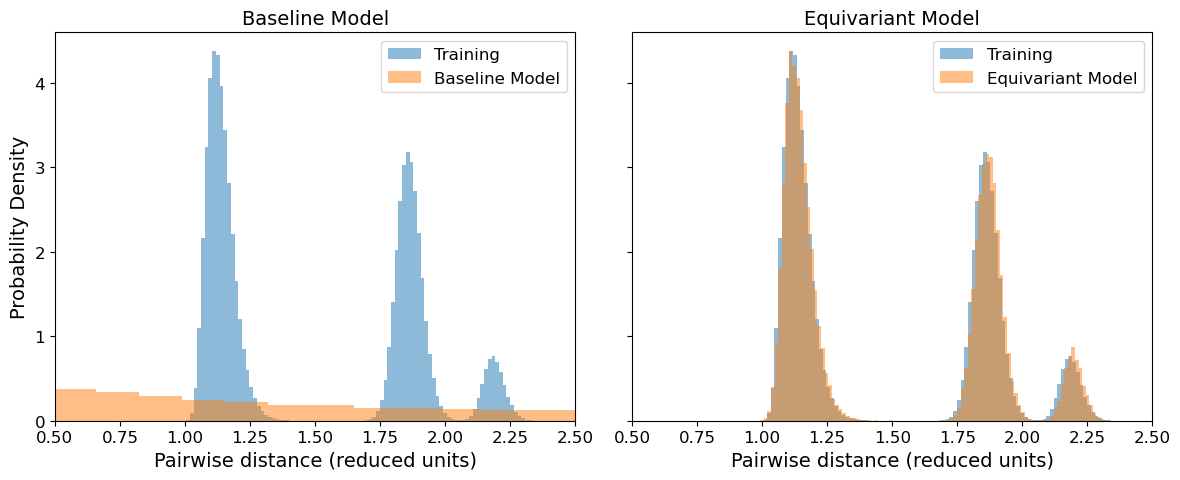

In [40]:
plt.rcParams.update({
    "font.size": 13,
    "axes.labelsize": 14,
    "axes.titlesize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
})

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Baseline
axes[0].hist(
    training_distances,
    bins=100,
    density=True,
    alpha=0.5,
    label="Training"
)

axes[0].hist(
    base_generated_distances,
    bins=100,
    density=True,
    alpha=0.5,
    label="Baseline Model"
)
axes[0].set_xlim(0.5, 2.5)
axes[0].set_xlabel("Pairwise distance (reduced units)")
axes[0].set_ylabel("Probability Density")
axes[0].set_title("Baseline Model")
axes[0].legend()

# Equivariant
axes[1].hist(
    training_distances,
    bins=100,
    density=True,
    alpha=0.5,
    label="Training"
)

axes[1].hist(
    equivariant_generated_distances,
    bins=100,
    density=True,
    alpha=0.5,
    label="Equivariant Model"
)

axes[1].set_xlim(0.5, 2.5)
axes[1].set_xlabel("Pairwise distance (reduced units)")
axes[1].set_title("Equivariant Model")
axes[1].legend()

plt.tight_layout()
plt.savefig("pairwise_distances.pdf", bbox_inches="tight")
plt.show()

In [41]:
from scipy.stats import wasserstein_distance

In [42]:
def wasserstein2_1d_quantile(u, v, n=1000):
    q = (np.arange(n) + 0.5) / n
    return np.sqrt(np.mean((np.quantile(u, q) - np.quantile(v, q)) ** 2))

In [43]:
rng = np.random.default_rng(42)

idx = rng.choice(len(training_configs_centered_tensor), size=1000, replace=False)

training_samples_1000 = training_configs_centered_tensor[idx]

In [44]:
training_energies_1000 = []

for sample in training_samples_1000:
    E = lj_energy_batch(sample.unsqueeze(0)).item()
    training_energies_1000.append(E)

training_energies_1000 = np.array(training_energies_1000)

In [45]:
W_equivariant_energies_new = wasserstein2_1d_quantile(training_energies_1000, equivariant_generated_energies)
print(W_equivariant_energies_new)

0.22756475226107506


In [47]:
W_equivariant_energies_LP = wasserstein2_1d_quantile(training_energies_1000, equivariant_generated_energies_LP)
print(W_equivariant_energies_LP)

0.07307379229040416


In [48]:
W_valid_baseline_energies_new = wasserstein2_1d_quantile(training_energies_1000, valid_baseline_generated_energies)
print(W_valid_baseline_energies_new)

29.572267335777646


In [49]:
W_baseline_energies_new = wasserstein2_1d_quantile(training_energies_1000, baseline_generated_energies)
print(W_baseline_energies_new)

6.102355950312833e+17


In [ ]:
training_distances_1000 = pairwise_distances_batch(training_samples_1000)

In [ ]:
equivariant_generated_distance_LP = pairwise_distances_batch(equivariant_samples_LP)

In [51]:
W_equivariant_pd = wasserstein2_1d_quantile(
    training_distances_1000,
    equivariant_generated_distances
)

print(W_equivariant_pd)

0.006837480921701325


In [54]:
W_equivariant_pd_LP = wasserstein2_1d_quantile(
    training_distances_1000,
    equivariant_generated_distance_LP
)

print(W_equivariant_pd_LP)

0.001695769894705179


In [56]:
W_baseline_pd = wasserstein2_1d_quantile(
    training_distances_1000,
    base_generated_distances
)
print(W_baseline_pd)

2.173164876628063


In [ ]:
valid_configs_pairwise_distances = pairwise_distances_batch(valid_configs)
W_baseline_pd_valid = wasserstein2_1d_quantile(
    training_distances_1000,
    valid_configs_pairwise_distances
)
print(W_baseline_pd_valid)

2.507664294604814


In [97]:
untrained_equivariant_model = ScoreNetwork(hidden_dim=64, num_layers=3)
untrained_equivariant_model.eval()

ScoreNetwork(
  (embedding): Linear(in_features=1, out_features=64, bias=True)
  (layers): ModuleList(
    (0-2): 3 x EGNNLayer(
      (message_mlp): MessageMLP(
        (net): Sequential(
          (0): Linear(in_features=130, out_features=64, bias=True)
          (1): SiLU()
          (2): Linear(in_features=64, out_features=64, bias=True)
          (3): SiLU()
        )
      )
      (feature_mlp): FeatureMLP(
        (net): Sequential(
          (0): Linear(in_features=128, out_features=64, bias=True)
          (1): SiLU()
          (2): Linear(in_features=64, out_features=64, bias=True)
        )
      )
      (coord_mlp): CoordMLP(
        (net): Sequential(
          (0): Linear(in_features=130, out_features=64, bias=True)
          (1): SiLU()
          (2): Linear(in_features=64, out_features=64, bias=True)
          (3): SiLU()
          (4): Linear(in_features=64, out_features=1, bias=True)
        )
      )
    )
  )
)

In [98]:
untrained_baseline_model = nn.Sequential(*layers)
untrained_baseline_model.eval()

Sequential(
  (0): Linear(in_features=40, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=128, bias=True)
  (3): ReLU()
  (4): Linear(in_features=128, out_features=128, bias=True)
  (5): ReLU()
  (6): Linear(in_features=128, out_features=39, bias=True)
)

In [105]:
x = training_configs_centered_tensor[0].reshape(13, 3)

sigma = torch.tensor([[0.5]])
log_sigma = torch.log(sigma)

translation = torch.tensor(
    [1.2, -0.7, 0.9]
)

x_translated = x + translation

with torch.no_grad():

    score_original_equivariant = untrained_equivariant_model(
        x.unsqueeze(0),
        log_sigma
    )

    score_translated_equivariant = untrained_equivariant_model(
        x_translated.unsqueeze(0),
        log_sigma
    )

    x_flat = x.reshape(1, 39)
    x_translated_flat = x_translated.reshape(1, 39)

    baseline_input_original = torch.cat(
        [x_flat, sigma],
        dim=1
    )

    baseline_input_translated = torch.cat(
        [x_translated_flat, sigma],
        dim=1
    )
    
    score_original_baseline = untrained_baseline_model(
        baseline_input_original
    )

    score_translated_baseline = untrained_baseline_model(
        baseline_input_translated
    )

In [ ]:
score_original_equivariant = score_original_equivariant.squeeze(0)
score_translated_equivariant = score_translated_equivariant.squeeze(0)

absolute_error = torch.norm(
    score_translated_equivariant - score_original_equivariant
).item()

relative_error = (
    torch.norm(score_translated_equivariant - score_original_equivariant)
    / torch.norm(score_original_equivariant)
).item()

print("Absolute translation error:", absolute_error)
print("Relative translation error:", relative_error)

Absolute translation error: 1.212241279580084e-10
Relative translation error: 3.514815034577623e-07


In [106]:
score_original_baseline = score_original_baseline.squeeze(0)
score_translated_baseline = score_translated_baseline.squeeze(0)

absolute_error_baseline = torch.norm(
    score_translated_baseline - score_original_baseline
).item()

relative_error_baseline = (
    torch.norm(score_translated_baseline - score_original_baseline)
    / torch.norm(score_original_baseline)
).item()

print("Absolute translation error (baseline):", absolute_error_baseline)
print("Relative translation error (baseline):", relative_error_baseline)

Absolute translation error (baseline): 0.23048365116119385
Relative translation error (baseline): 0.08224000036716461


In [124]:
Q = torch.linalg.qr(torch.randn(3,3))[0]
Q = Q * torch.sign(torch.det(Q))

with torch.no_grad():
    score_rotated_equivariant = untrained_equivariant_model(x.unsqueeze(0) @ Q, log_sigma)

rotation_error = ((score_rotated_equivariant - score_original_equivariant.unsqueeze(0) @ Q).norm() / score_original_equivariant.unsqueeze(0).norm())

print("Rotation relative error:", rotation_error.item())

Rotation relative error: 3.39140740379662e-07


In [116]:
x_rotated =x.unsqueeze(0) @ Q
x_rotated_flat = x_rotated.reshape(-1,39)

with torch.no_grad():
    score_rotated_baseline = untrained_baseline_model(torch.cat([x_rotated_flat, sigma], dim=1))

In [121]:
score_original_baseline_3d = score_original_baseline.reshape(1, 13, 3)
score_rotated_baseline_3d = score_rotated_baseline.reshape(1, 13, 3)

In [125]:
score_original_baseline_rotated = score_original_baseline_3d @ Q
rotation_error_baseline = (
    (score_rotated_baseline_3d - score_original_baseline_rotated).norm()
    / score_original_baseline_3d.norm()
)

print(rotation_error_baseline.item())

1.6657277345657349


In [126]:
permutation = torch.randperm(13)

x_permuted = x[permutation]

In [127]:
score_permuted_equivariant = untrained_equivariant_model(
        x_permuted.unsqueeze(0),
        log_sigma
    )

In [128]:
score_original_permuted = (
    score_original_equivariant[:, permutation, :]
)

In [129]:
permutation_error_equivariant = (
    (score_permuted_equivariant - score_original_permuted).norm()
    / score_original_permuted.norm()
)

print(
    "EGNN permutation error:",
    permutation_error_equivariant.item()
)

EGNN permutation error: 3.1757267038301507e-07


In [130]:
baseline_input_permuted = torch.cat(
        [x_permuted.reshape(1, 39), sigma],
        dim=1
    )

score_permuted_baseline = untrained_baseline_model(
        baseline_input_permuted
    )

In [131]:
score_original_baseline_3d = (
    score_original_baseline.reshape(1, 13, 3)
)

score_permuted_baseline_3d = (
    score_permuted_baseline.reshape(1, 13, 3)
)

In [132]:
score_original_baseline_permuted = (
    score_original_baseline_3d[:, permutation, :]
)

In [133]:
permutation_error_baseline = (
    (
        score_permuted_baseline_3d
        - score_original_baseline_permuted
    ).norm()
    / score_original_baseline_permuted.norm()
)

print(
    "Baseline permutation error:",
    permutation_error_baseline.item()
)

Baseline permutation error: 3.3913135528564453


In [134]:
n_train_configs = 500
n_noise = 100
Temp = 0.1
beta = 1.0 / Temp
x0_train = training_configs_centered_tensor[:n_train_configs]

sigma_values = [0.01]

In [135]:
import torch.nn.functional as F

In [ ]:
results_train = []

for sigma_value in sigma_values:

    sigma = torch.tensor(sigma_value)

    cos_physics_all = []
    norm_ratio_physics_all = []

    for repeat in range(n_noise):


        z = torch.randn_like(x0_train)
        z = z - z.mean(dim=1, keepdim=True)


        x_tilde = x0_train + sigma * z


        log_sigma = torch.full((n_train_configs, 1), np.log(sigma_value))

        with torch.no_grad():
            f_pred = equivariant_model(x_tilde, log_sigma)

        score_model = f_pred / sigma

        x_phys = (x_tilde.detach().clone().requires_grad_(True))

        energies = lj_energy_batch(x_phys)
        total_energy = energies.sum()

        grad_U = torch.autograd.grad(total_energy, x_phys)[0]

        score_physics = -beta * grad_U


        model_flat = score_model.reshape(n_train_configs, -1)
        physics_flat = score_physics.reshape(n_train_configs, -1)

        cos_physics = F.cosine_similarity(model_flat, physics_flat, dim=1)

        model_norm = torch.norm(model_flat, dim=1)
        physics_norm = torch.norm(physics_flat, dim=1)

        norm_ratio_physics = model_norm / physics_norm

        cos_physics_all.extend(cos_physics.detach().cpu().numpy())

        norm_ratio_physics_all.extend(norm_ratio_physics.detach().cpu().numpy())


    results_train.append({
        "sigma": sigma_value,
        "cos_physics": np.mean(cos_physics_all),
        "norm_ratio_physics": np.mean(norm_ratio_physics_all)
    })

In [151]:
for result in results_train:
    print(
        f"sigma = {result['sigma']:.4f}, "
        f"cos_physics = {result['cos_physics']:.4f}, "
        f"norm_physics = {result['norm_ratio_physics']:.4f}"
    )

sigma = 0.0100, cos_physics = 0.9549, norm_physics = 0.9059


In [152]:
equivariant_generated_energies.mean()

np.float64(-42.31093534469605)

In [55]:
equivariant_generated_energies_LP.mean()

np.float64(-42.47842084884643)

In [57]:
T_eff_LP = (equivariant_generated_energies_LP.mean()-U_min)/(33/2)
T_eff = (equivariant_generated_energies.mean()-U_min)/(33/2)
print(T_eff_LP)
print(T_eff)

0.11202297885779186
0.12271651625199723


In [8]:
equivariant_loss_history = torch.load(
    "lj13_loss_history_strategy_new.pth",
    weights_only=True
)

checkpoint = torch.load(
    "baseline_model_data.pth",
    weights_only=False
)

baseline_loss_history = checkpoint["loss_history"]

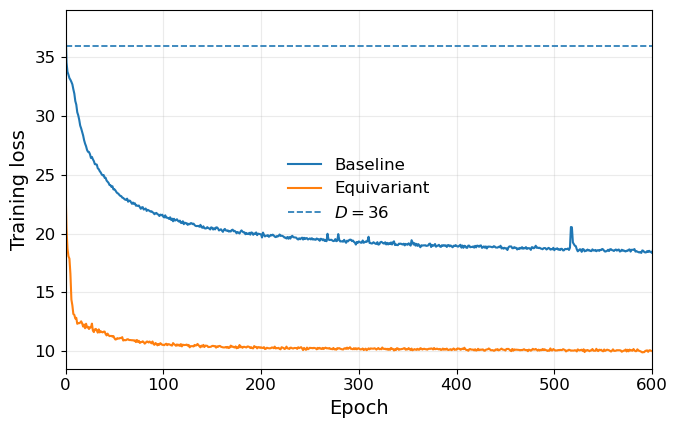

In [19]:
import matplotlib.pyplot as plt
import numpy as np

# Reference loss
D = 36
plt.rcParams.update({
    "font.size": 14,
    "axes.labelsize": 14,
    "axes.titlesize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
})
fig, ax = plt.subplots(figsize=(7, 4.5))

# Training losses
ax.plot(
    np.arange(len(baseline_loss_history)),
    baseline_loss_history,
    linewidth=1.5,
    label="Baseline"
)

ax.plot(
    np.arange(len(equivariant_loss_history)),
    equivariant_loss_history,
    linewidth=1.5,
    label="Equivariant"
)

# Zero-score reference
ax.axhline(
    D,
    linestyle="--",
    linewidth=1.2,
    label=fr"$D={D}$"
)

# Axes
ax.set_xlim(0, 600)
ax.set_xticks(np.arange(0, 601, 100))

ax.set_xlabel("Epoch")
ax.set_ylabel("Training loss")

# Tick formatting
ax.tick_params(axis="both")

# Grid
ax.grid(True, alpha=0.25)

# Legend
ax.legend(
    frameon=False
)

# Layout
fig.tight_layout()

# Save high-resolution version
fig.savefig(
    "training_loss_comparison.pdf",
    bbox_inches="tight"
)

fig.savefig(
    "training_loss_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()